# 1 Skeleton: from crowd data to a first model

This notebook narrates the walking skeleton (leaves 1.1–1.7). It only calls functions from `src/europapark_crowd`.

The goal is to rank the open days of a season by crowd level, so a visitor can pick a quiet day. The crowd level is the daily crowd percentage from the Queue-Times.com month calendar ([ADR 0002](../docs/adr/0002-queue-times-crowd-percentage.md)). It is a rank against all of the park's days, not attendance. Terms follow [GLOSSARY.md](../GLOSSARY.md).

Data: Powered by [Queue-Times.com](https://queue-times.com/parks/51/calendar).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from europapark_crowd.baselines import last_season_predictor, savvy_visitor_predictor
from europapark_crowd.evaluate import RUNS, actual_quiet, random_predictor, score
from europapark_crowd.linear import linear_predictor
from europapark_crowd.open_days import load_open_days
from europapark_crowd.parse import load_crowd_table
from europapark_crowd.windows import load_windows, season_windows

## What the crowd data looks like

`load_crowd_table()` parses the cached month pages, March to November of 2019 and 2022–2025. Each date appears once. Closed days have no crowd level.

In [2]:
table = load_crowd_table()
print("rows:", len(table))
print("open days:", table["is_open"].sum())
print("closed days:", (~table["is_open"]).sum())

rows: 1375
open days: 1230
closed days: 145


`load_open_days()` keeps the open days and labels each with its season from the date alone. The summer season ends on the first Sunday of November, so HALLOWinter days fall outside it. Only the summer seasons are modelled for now.

In [3]:
days = load_open_days()
print("open summer days:", len(days))
days.groupby("season")["crowd_level"].describe().round(1)

open summer days: 1118


,count,mean,std,min,25%,50%,75%,max
season,,,,,,,,
summer 2019,212.0,50.1,29.2,2.0,21.8,50.5,73.2,99.0
summer 2022,226.0,55.8,30.6,1.0,30.0,58.0,84.0,99.0
summer 2023,226.0,60.8,25.0,3.0,41.0,61.0,80.8,100.0
summer 2024,228.0,61.6,22.7,7.0,45.0,64.0,80.0,99.0
summer 2025,226.0,57.2,22.7,8.0,40.2,56.0,75.0,99.0


Each season starts in late March or early April and ends in early November. The crowd level swings widely from day to day inside each season.

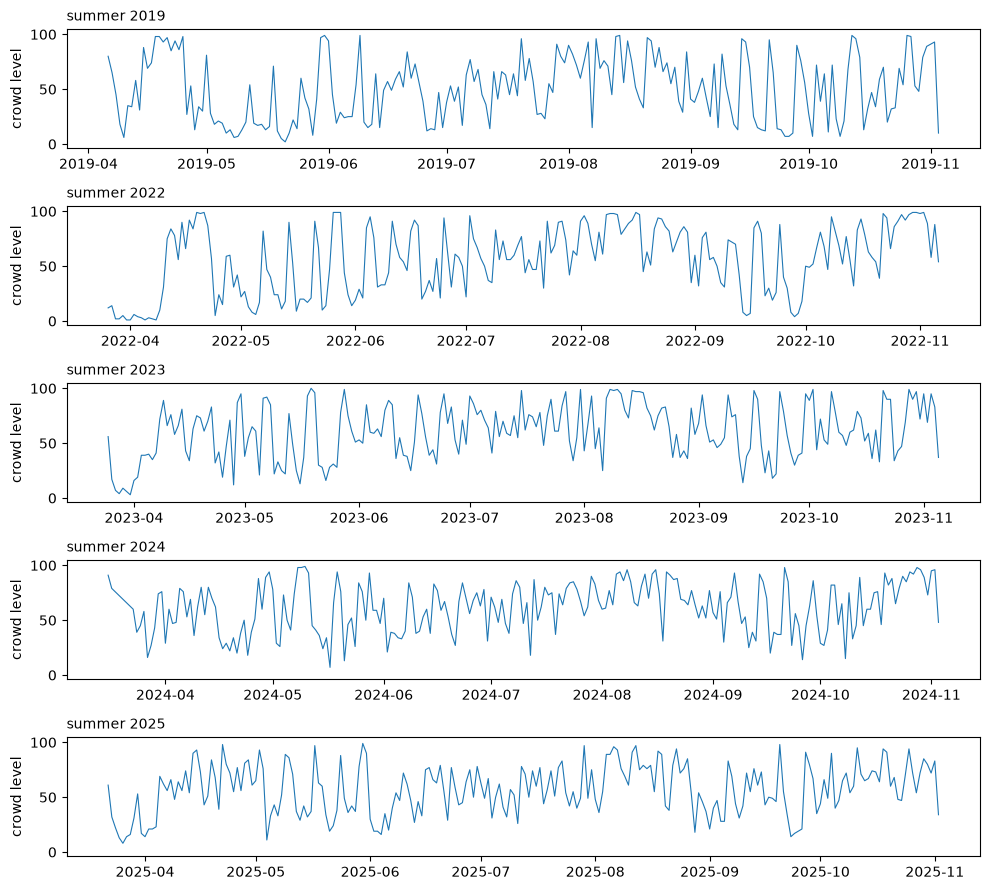

In [4]:
fig, axes = plt.subplots(len(days["season"].unique()), 1, figsize=(10, 9), sharey=True)
for ax, (season, group) in zip(axes, days.groupby("season")):
    ax.plot(group["date"], group["crowd_level"], lw=0.8)
    ax.set_title(season, loc="left", fontsize=10)
    ax.set_ylabel("crowd level")
fig.tight_layout()

Weekday is the strongest pattern the calendar alone gives. Saturday is the busiest day in every season, and Sunday and Monday come next. The quietest weekday changes from season to season: Tuesday, Wednesday or Friday.

season,summer 2019,summer 2022,summer 2023,summer 2024,summer 2025
date,,,,,
Monday,50.4,56.8,63.8,63.7,55.3
Tuesday,42.5,52.6,50.8,60.9,58.8
Wednesday,41.0,52.2,54.7,55.6,51.7
Thursday,49.5,50.9,58.4,58.0,53.0
Friday,41.5,43.2,52.8,52.9,52.8
Saturday,71.1,74.1,80.2,76.9,73.2
Sunday,53.8,60.4,63.9,62.1,55.0


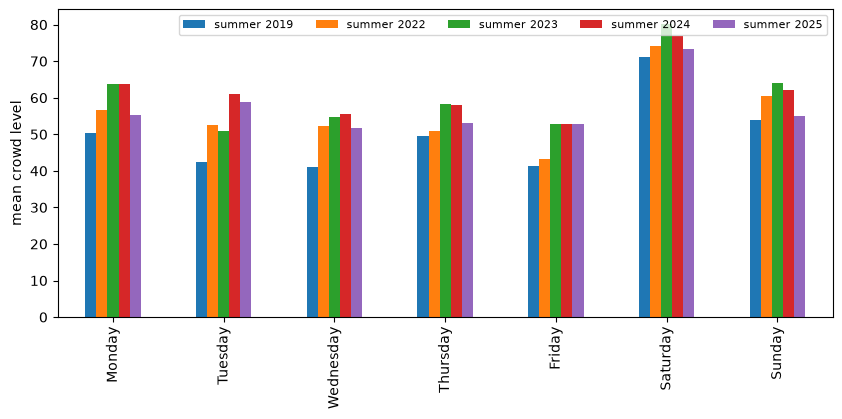

In [5]:
weekday_means = days.pivot_table(
    index=days["date"].dt.day_name(), columns="season", values="crowd_level", aggfunc="mean"
).reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
weekday_means.plot.bar(figsize=(10, 4), ylabel="mean crowd level", xlabel="")
plt.legend(ncols=5, fontsize=8)
weekday_means.round(1)

## The COVID gap

The modelled seasons jump from summer 2019 to summer 2022. Summers 2020 and 2021 are left out on purpose ([ADR 0003](../docs/adr/0003-evaluation-seasons.md)):

- COVID closures and capacity caps distorted crowd levels in 2020 and 2021.
- Free school-holiday data limits the start. French holidays start in late 2017 and Swiss holidays only in December 2019, so the history starts at 2019.

The fetcher never requests those years, so they are absent from the cache rather than filtered out here.

In [6]:
days.groupby("season")["date"].agg(first="min", last="max", days="count")

,first,last,days
season,,,
summer 2019,2019-04-06,2019-11-03,212
summer 2022,2022-03-26,2022-11-06,226
summer 2023,2023-03-25,2023-11-05,226
summer 2024,2024-03-16,2024-11-03,228
summer 2025,2025-03-22,2025-11-02,226


Each test season is predicted from all earlier seasons. Each run has two stages: the validation stage fits on the train seasons and scores the validation season; the test stage refits with the validation season added and scores the test season. Summer 2026 is the holdout season and stays unseen until the end.

In [7]:
pd.DataFrame(RUNS).set_index("run")

,train,validate,test
run,,,
run 1,"[summer 2019, summer 2022]",summer 2023,summer 2024
run 2,"[summer 2019, summer 2022, summer 2023]",summer 2024,summer 2025


## How quiet days are defined

An actual quiet day is an open day at or below its season's 25th-percentile crowd level. Days tied at the cutoff all count, so slightly more than a quarter of each season is quiet.

In [8]:
quiet = days.groupby("season")["crowd_level"].agg(
    cutoff=lambda s: s.quantile(0.25),
    quiet_days=lambda s: actual_quiet(s).sum(),
    days="count",
)
quiet["quiet_share"] = (quiet["quiet_days"] / quiet["days"]).round(3)
quiet

,cutoff,quiet_days,days,quiet_share
season,,,,
summer 2019,21.75,53,212,0.25
summer 2022,30.0,58,226,0.257
summer 2023,41.0,59,226,0.261
summer 2024,45.0,62,228,0.272
summer 2025,40.25,57,226,0.252


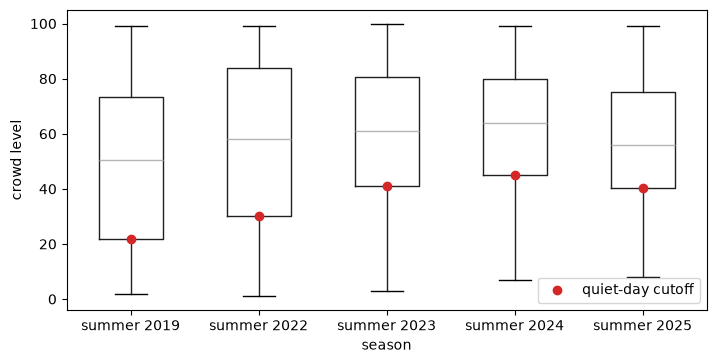

In [9]:
ax = days.boxplot(column="crowd_level", by="season", figsize=(8, 4), grid=False)
ax.scatter(range(1, len(quiet) + 1), quiet["cutoff"], color="C3", zorder=3, label="quiet-day cutoff")
ax.set_title("")
ax.set_ylabel("crowd level")
ax.legend()
plt.suptitle("");

Every predictor is scored on three metrics:

- **Quiet-day precision**: the share of predicted quiet days that were actual quiet days. The predicted quiet days are exactly the quarter of the season with the lowest predictions, with ties broken in a seeded random order. A random guesser lands slightly above 0.25.
- **Spearman correlation**: how well the whole season ranking matches the actual ranking.
- **Regret**: how many crowd-level points the predicted quietest day of a visit window sits above the window's actual quietest day, averaged over the season's visit windows. Lower is better.

A visit window is a set of open days a visitor is restricted to. These are the windows of summer 2024:

In [10]:
season_2024 = days[days["season"] == "summer 2024"]
windows_2024 = season_windows(season_2024, load_windows())
pd.Series({name: mask.sum() for name, mask in windows_2024.items()}, name="open days").to_frame()

,open days
BW Easter holidays,14
BW Whitsun holidays,11
BW summer holidays,45
BW autumn holidays,4
French zone B summer holidays,58
Basel-Stadt summer holidays,43
spring,72
summer,92
autumn,64
Saturdays in March,3


## Baselines

Two fixed rules set the bar to beat, next to the random guesser as the chance level:

- **Savvy-visitor baseline**: weekends and Baden-Württemberg school and public holidays are busy, every other open day is quiet.
- **Last-season baseline**: copy last season's crowd level on the day with the same ISO week and weekday.

In [11]:
windows = load_windows()
predictors = {
    "random": random_predictor,
    "savvy visitor": savvy_visitor_predictor,
    "last season": last_season_predictor,
}
baselines = pd.concat(
    {name: score(predictor, days, windows) for name, predictor in predictors.items()},
    names=["model"],
)
baselines.round(3)

season  days  precision  spearman  regret
model         run   stage                                                   
random        run 1 validate  summer 2023   226      0.339    -0.033  32.312
                    test      summer 2024   228      0.298     0.045  15.000
              run 2 validate  summer 2024   228      0.298     0.045  15.000
                    test      summer 2025   226      0.339     0.006  35.059
savvy visitor run 1 validate  summer 2023   226      0.429     0.450  26.038
                    test      summer 2024   228      0.368     0.355  28.454
              run 2 validate  summer 2024   228      0.368     0.355  28.454
                    test      summer 2025   226      0.429     0.352  23.816
last season   run 1 validate  summer 2023   226      0.625     0.515  14.891
                    test      summer 2024   228      0.386     0.404  23.294
              run 2 validate  summer 2024   228      0.386     0.404  23.294
                    test      summer 2025   226      0.429     0.435  19.059

Both baselines beat chance on precision and Spearman. The last-season baseline is the stronger one. Its precision of 0.625 on summer 2023 falls to 0.39–0.43 on later seasons, so one good season is not the norm.

Run 1 test and run 2 validation both fit on 2019, 2022 and 2023 and score 2024, so their rows match exactly.

## First model

The first model is an untuned ridge regression on the weekday feature only, one-hot encoded. It proves the full path works: open-day table, feature list, model, harness.

In [12]:
results = pd.concat(
    [baselines, pd.concat({"linear (weekday)": score(linear_predictor, days, windows)}, names=["model"])]
)
results.round(3)

season  days  precision  spearman  \
model            run   stage                                              
random           run 1 validate  summer 2023   226      0.339    -0.033   
                       test      summer 2024   228      0.298     0.045   
                 run 2 validate  summer 2024   228      0.298     0.045   
                       test      summer 2025   226      0.339     0.006   
savvy visitor    run 1 validate  summer 2023   226      0.429     0.450   
                       test      summer 2024   228      0.368     0.355   
                 run 2 validate  summer 2024   228      0.368     0.355   
                       test      summer 2025   226      0.429     0.352   
last season      run 1 validate  summer 2023   226      0.625     0.515   
                       test      summer 2024   228      0.386     0.404   
                 run 2 validate  summer 2024   228      0.386     0.404   
                       test      summer 2025   226      0.429     0.435   
linear (weekday) run 1 validate  summer 2023   226      0.339     0.334   
                       test      summer 2024   228      0.351     0.258   
                 run 2 validate  summer 2024   228      0.351     0.258   
                       test      summer 2025   226      0.286     0.204   

                                 regret  
model            run   stage             
random           run 1 validate  32.312  
                       test      15.000  
                 run 2 validate  15.000  
                       test      35.059  
savvy visitor    run 1 validate  26.038  
                       test      28.454  
                 run 2 validate  28.454  
                       test      23.816  
last season      run 1 validate  14.891  
                       test      23.294  
                 run 2 validate  23.294  
                       test      19.059  
linear (weekday) run 1 validate  25.899  
                       test      27.398  
                 run 2 validate  27.398  
                       test      22.153

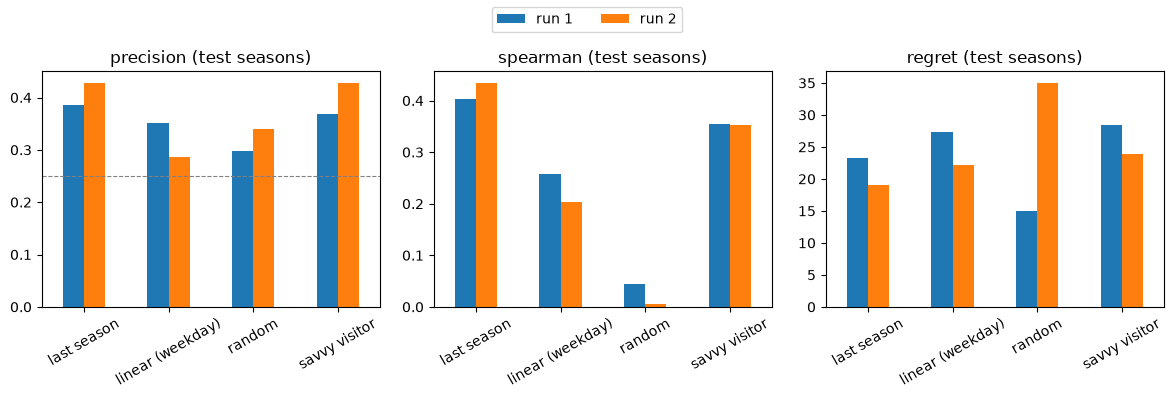

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
test = results.xs("test", level="stage")
for ax, metric in zip(axes, ["precision", "spearman", "regret"]):
    test[metric].unstack("run").plot.bar(ax=ax, legend=False, rot=30, xlabel="")
    ax.set_title(f"{metric} (test seasons)")
axes[0].axhline(0.25, color="grey", ls="--", lw=0.8)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncols=2)
fig.tight_layout(rect=(0, 0, 1, 0.92))

## Takeaway

- The weekday model ranks the season better than chance (Spearman 0.20–0.33) but stays below both baselines.
- Its quiet-day precision sits at chance level. Weekday alone gives only 7 distinct predictions, so the tie-break decides which days fill the predicted quiet quarter.
- The last-season baseline is the bar to beat. The next branches add calendar features (branch 2) and holiday pressure (branch 3) to the same feature list.